# Test Metrics on Rings and GMM bumps

Evaluating Concordance, Cross-Concordance and FOSCTTM (Fraction of Samples Closer Than the True Match).


In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")

from ne_aligned_utils.test_metrics_utils import (
    compute_metric_row,
    format_gmm_step_label,
    format_ring_step_label,
    gmm_scatter,
    gmm_shift_x,
    make_corresponded_gmm,
    make_ring,
    rotate,
    scale_radius,
    select_steps_for_row,
    shift_x,
    squash_y,
)

SEED = 7
K = 50
np.random.seed(SEED)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True


## Ring Samples

In [51]:
ring_size_modes = {
    "equal": (600, 600),
    "five_x": (600, 3000),
}

ring_families = {
    "rotation_deg": [1, 5, 10, 20, 30, 45, 90, 180],
    "shift_right": [0.0, 0.75, 1.5, 2.25, 3.0],
    "radius_growth": [0.6, 0.8, 1.0, 1.2, 1.4],
    "oval_squash": [0.9, 0.75, 0.6, 0.45, 0.3],
}

rows = []
ring_plot_examples = {}

for size_mode, (n0, n1) in ring_size_modes.items():
    x0_ref = make_ring(n0, seed=SEED)
    if size_mode == "equal":
        
        x1_ref = x0_ref.copy()
    else:
        x1_ref = make_ring(n1, seed=SEED + 1)

    y0 = x0_ref.copy()

    for family, steps in ring_families.items():
        for step in steps:
            if family == "rotation_deg":
                y1 = rotate(x1_ref, step)
            elif family == "shift_right":
                y1 = shift_x(x1_ref, step)
            elif family == "radius_growth":
                y1 = scale_radius(x1_ref, step)
            elif family == "oval_squash":
                y1 = squash_y(x1_ref, step)
            else:
                raise ValueError(f"Unknown family: {family}")

            m = compute_metric_row(x0_ref, x1_ref, y0, y1, k=K)
            rows.append({
                "dataset": "rings",
                "size_mode": size_mode,
                "family": family,
                "step": float(step),
                "concordance": m["concordance"],
                "cross_concordance": m["cross_concordance"],
                "foscttm": m["foscttm"],
                "foscttm_mode": m["foscttm_mode"],
            })

            
            ring_plot_examples[(size_mode, family, float(step))] = (y0.copy(), y1.copy())

df_rings = pd.DataFrame(rows)
df_rings = df_rings.sort_values(["family", "size_mode", "step"]).reset_index(drop=True)

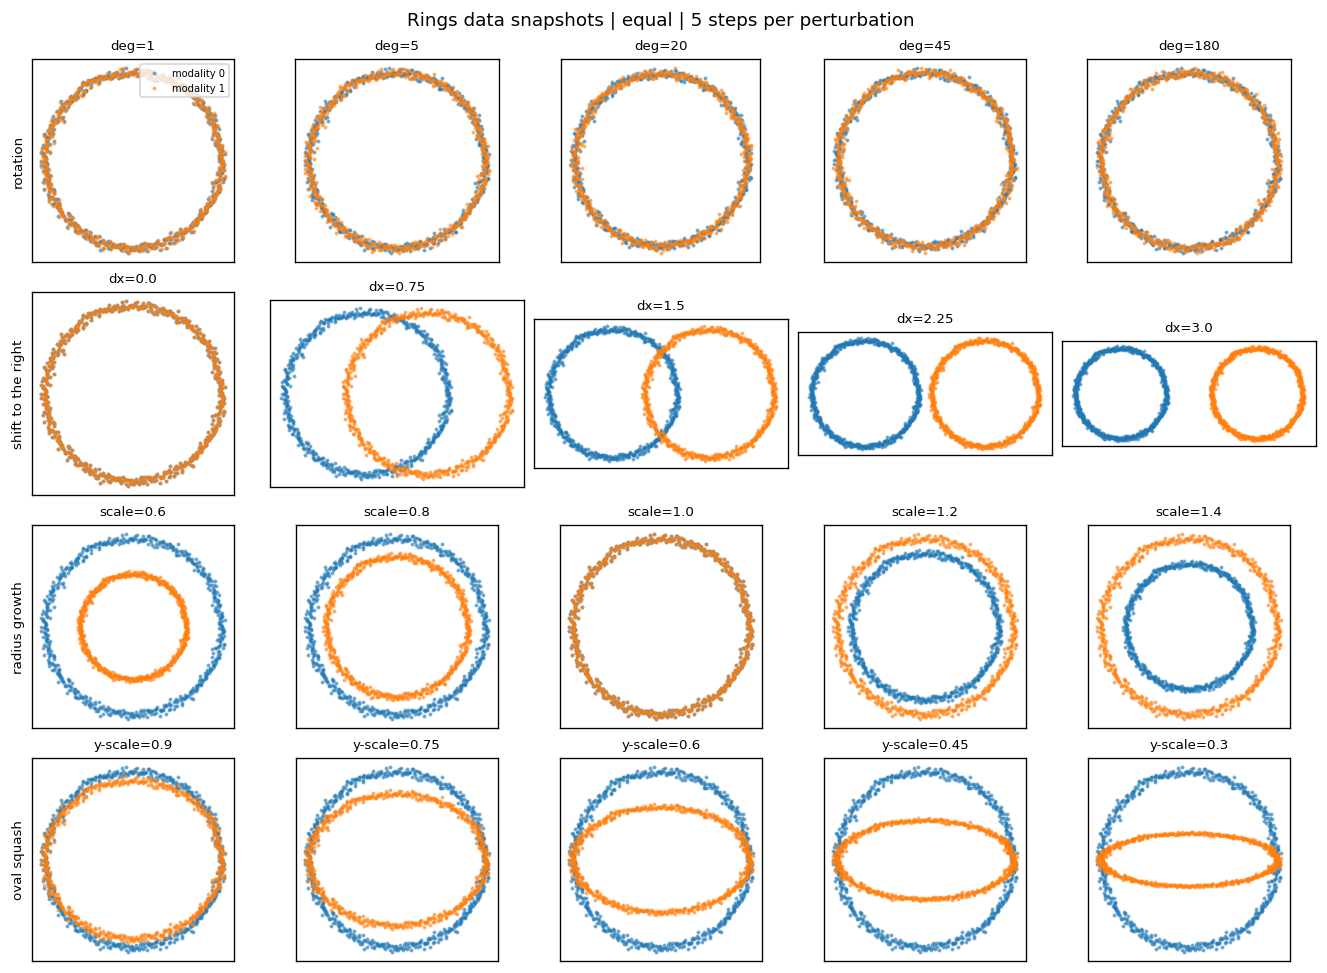

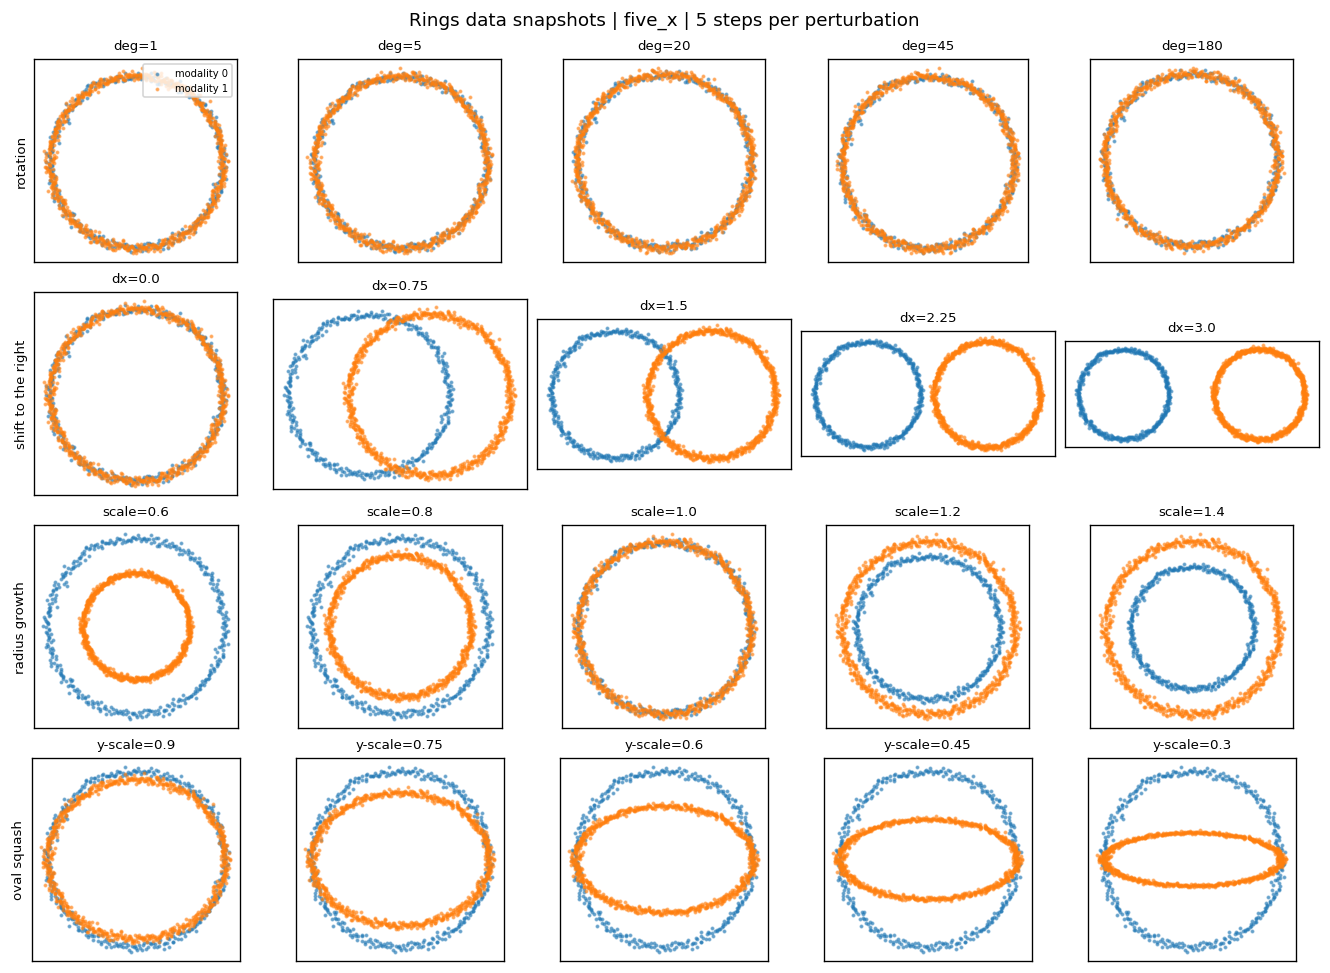

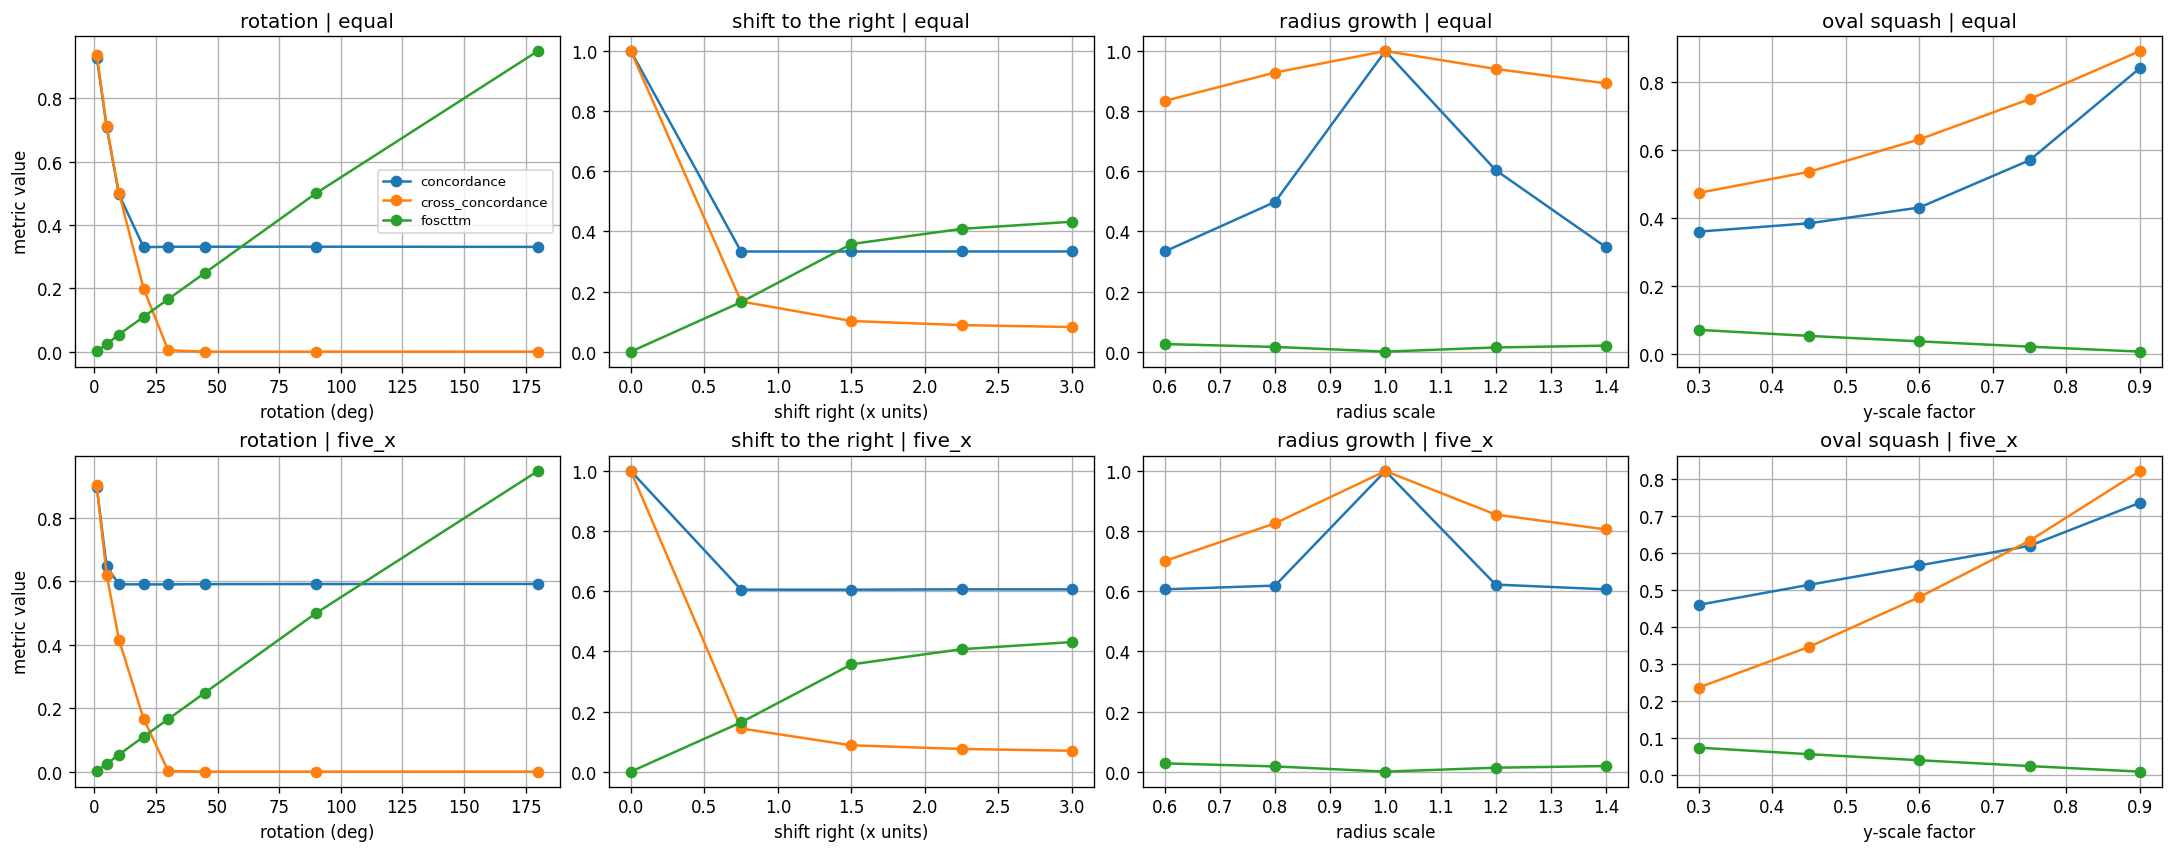

In [53]:
families = ["rotation_deg", "shift_right", "radius_growth", "oval_squash"]
size_order = ["equal", "five_x"]
n_cols = 5

family_display = {
    "rotation_deg": "rotation",
    "shift_right": "shift to the right",
    "radius_growth": "radius growth",
    "oval_squash": "oval squash",
}
family_xunit = {
    "rotation_deg": "rotation (deg)",
    "shift_right": "shift right (x units)",
    "radius_growth": "radius scale",
    "oval_squash": "y-scale factor",
}

for size_mode in size_order:
    fig, axes = plt.subplots(
        len(families),
        n_cols,
        figsize=(n_cols * 2.2, len(families) * 2.0),
        constrained_layout=True,
    )

    for i, fam in enumerate(families):
        steps_to_plot = select_steps_for_row(ring_families[fam], n_cols=n_cols)

        for j, step in enumerate(steps_to_plot):
            ax = axes[i, j]
            y0, y1 = ring_plot_examples[(size_mode, fam, float(step))]

            
            if size_mode == "five_x":
                idx0 = np.linspace(0, len(y0) - 1, min(400, len(y0)), dtype=int)
                idx1 = np.linspace(0, len(y1) - 1, min(800, len(y1)), dtype=int)
                yy0, yy1 = y0[idx0], y1[idx1]
            else:
                yy0, yy1 = y0, y1

            ax.scatter(yy0[:, 0], yy0[:, 1], s=2, alpha=0.5, label="modality 0")
            ax.scatter(yy1[:, 0], yy1[:, 1], s=2, alpha=0.5, label="modality 1")
            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(format_ring_step_label(fam, step), fontsize=8)

            if j == 0:
                ax.set_ylabel(family_display[fam], fontsize=8)
            if i == 0 and j == 0:
                ax.legend(loc="upper right", fontsize=6)

    fig.suptitle(f"Rings data snapshots | {size_mode} | 5 steps per perturbation", fontsize=11)
    plt.show()

metrics = ["concordance", "cross_concordance", "foscttm"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=False, constrained_layout=True)

for r, size_mode in enumerate(size_order):
    for c, fam in enumerate(families):
        ax = axes[r, c]
        sub = df_rings[(df_rings["size_mode"] == size_mode) & (df_rings["family"] == fam)].sort_values("step")
        for m in metrics:
            ax.plot(sub["step"], sub[m], marker="o", label=m)
        ax.set_title(f"{family_display[fam]} | {size_mode}")
        ax.set_xlabel(family_xunit[fam])
        if c == 0:
            ax.set_ylabel("metric value")
        if r == 0 and c == 0:
            ax.legend(fontsize=8)

plt.show()

ring_summary = df_rings[[
    "family", "size_mode", "step", "concordance", "cross_concordance", "foscttm", "foscttm_mode"
]].copy()
ring_summary = ring_summary.sort_values(["family", "size_mode", "step"]).round(4)


## GMM Experiments

In [54]:
gmm_size_modes = {
    "equal": (600, 600),
    "n0_5x_n1": (3000, 600),
}

gmm_shift_steps = [0.0, 0.5, 1.0, 1.5, 2.0]
base_scatter_std = 0.6

gmm_scatter_steps = [0.02, 0.2, base_scatter_std, 0.9, 1.2]

rows = []
gmm_plot_examples = {}

for size_mode, (n0, n1) in gmm_size_modes.items():
    x0_gmm, x1_gmm, labels0, labels1, gmm_means = make_corresponded_gmm(
        n0=n0, n1=n1, q=6, mean_scale=5.0, base_std=base_scatter_std, seed=SEED
    )
    y0_gmm = x0_gmm.copy()

    for dx in gmm_shift_steps:
        y1 = gmm_shift_x(x1_gmm, dx)
        m = compute_metric_row(x0_gmm, x1_gmm, y0_gmm, y1, k=K)
        rows.append({
            "dataset": "gmm",
            "size_mode": size_mode,
            "family": "shift_right",
            "step": float(dx),
            "concordance": m["concordance"],
            "cross_concordance": m["cross_concordance"],
            "foscttm": m["foscttm"],
            "foscttm_mode": m["foscttm_mode"],
        })
        gmm_plot_examples[(size_mode, "shift_right", float(dx))] = (y0_gmm.copy(), y1.copy())

    for s in gmm_scatter_steps:
        if np.isclose(s, base_scatter_std):
           
            y1 = x1_gmm.copy()
        else:
            seed_offset = 0 if size_mode == "equal" else 10000
            y1 = gmm_scatter(gmm_means, labels1, s, seed=SEED + int(s * 1000) + 100 + seed_offset)

        m = compute_metric_row(x0_gmm, x1_gmm, y0_gmm, y1, k=K)
        rows.append({
            "dataset": "gmm",
            "size_mode": size_mode,
            "family": "scatter",
            "step": float(s),
            "concordance": m["concordance"],
            "cross_concordance": m["cross_concordance"],
            "foscttm": m["foscttm"],
            "foscttm_mode": m["foscttm_mode"],
        })
        gmm_plot_examples[(size_mode, "scatter", float(s))] = (y0_gmm.copy(), y1.copy())

df_gmm = pd.DataFrame(rows)
df_gmm = df_gmm.sort_values(["size_mode", "family", "step"]).reset_index(drop=True)


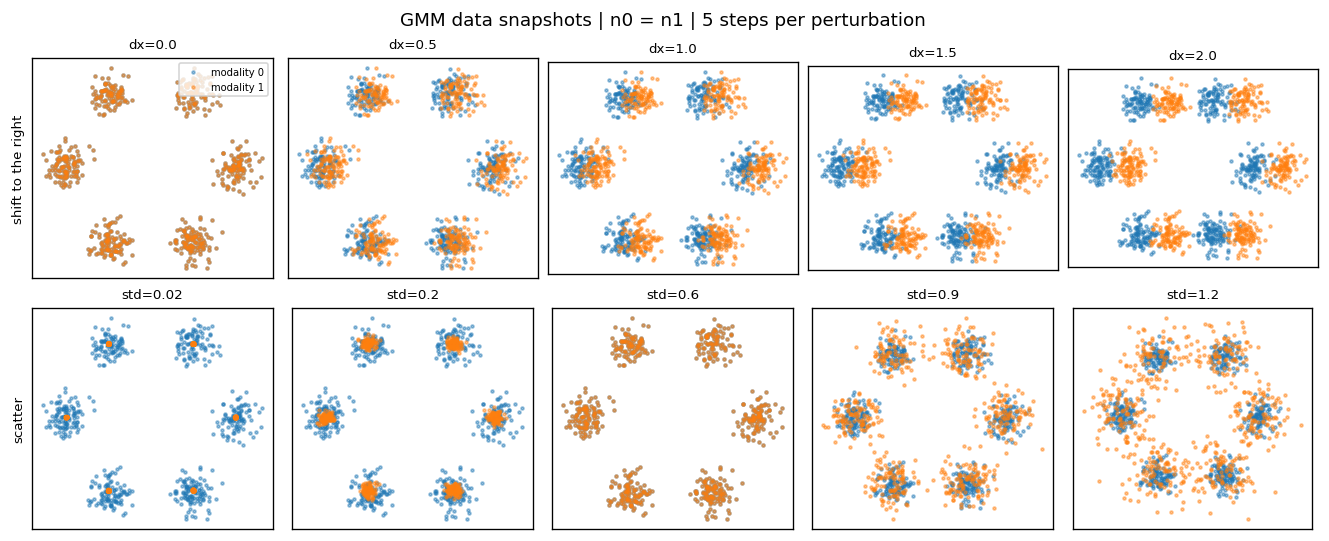

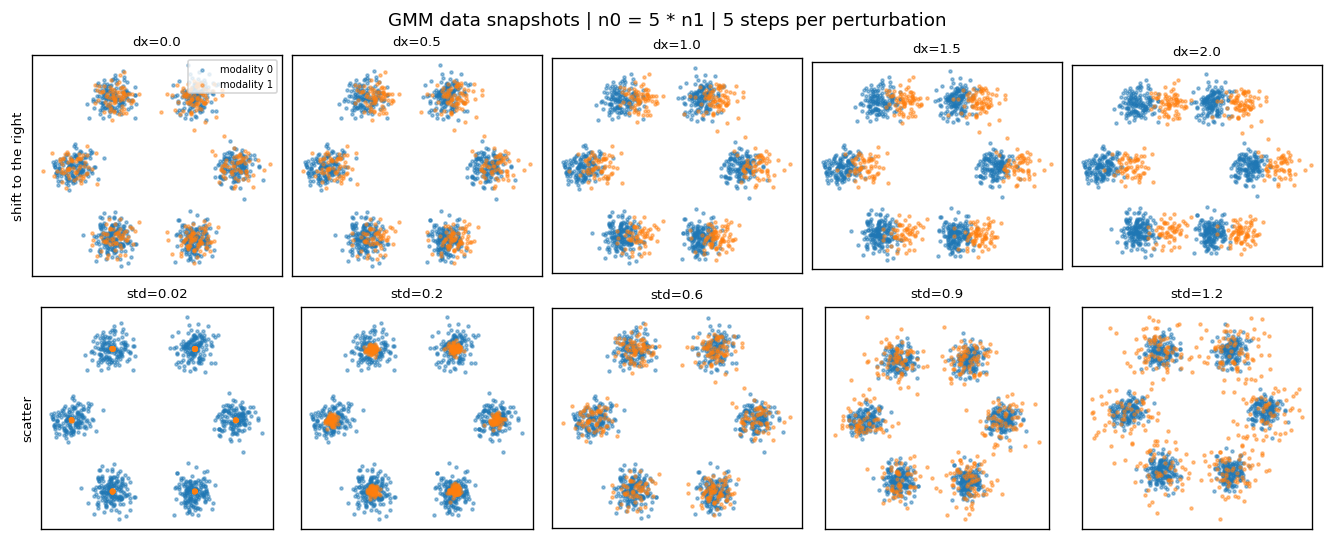

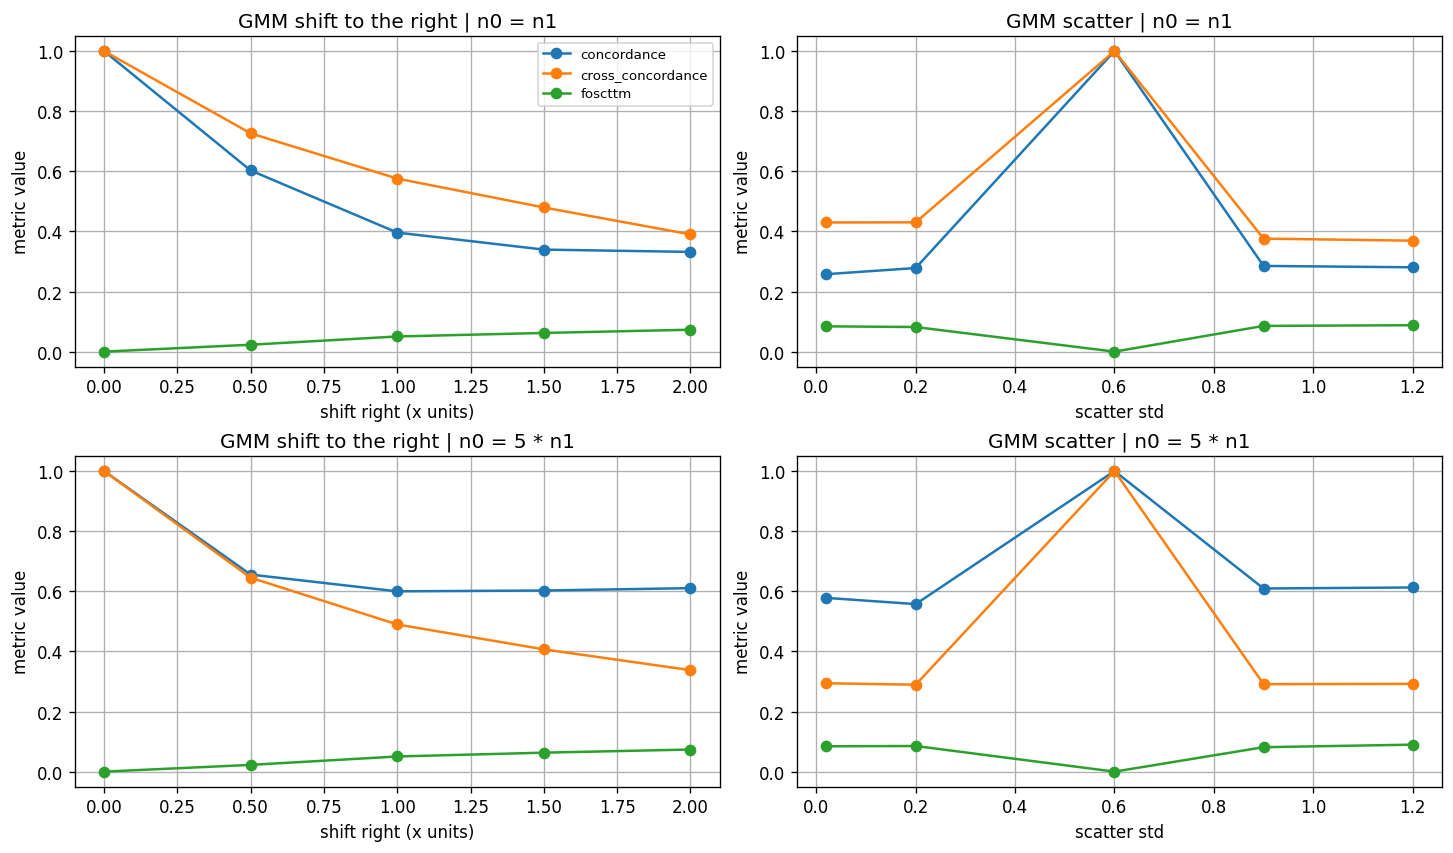

In [56]:
families = ["shift_right", "scatter"]
size_order = ["equal", "n0_5x_n1"]
n_cols = 5

family_display = {
    "shift_right": "shift to the right",
    "scatter": "scatter",
}
family_xunit = {
    "shift_right": "shift right (x units)",
    "scatter": "scatter std",
}
size_display = {
    "equal": "n0 = n1",
    "n0_5x_n1": "n0 = 5 * n1",
}

for size_mode in size_order:
    fig, axes = plt.subplots(
        len(families),
        n_cols,
        figsize=(n_cols * 2.2, len(families) * 2.2),
        constrained_layout=True,
    )

    for i, fam in enumerate(families):
        steps = sorted(df_gmm[(df_gmm["size_mode"] == size_mode) & (df_gmm["family"] == fam)]["step"].unique())

        for j, step in enumerate(steps[:n_cols]):
            ax = axes[i, j]
            y0, y1 = gmm_plot_examples[(size_mode, fam, float(step))]

            if size_mode == "n0_5x_n1":
                idx0 = np.linspace(0, len(y0) - 1, min(900, len(y0)), dtype=int)
                idx1 = np.linspace(0, len(y1) - 1, min(400, len(y1)), dtype=int)
                yy0, yy1 = y0[idx0], y1[idx1]
            else:
                yy0, yy1 = y0, y1

            ax.scatter(yy0[:, 0], yy0[:, 1], s=3, alpha=0.45, label="modality 0")
            ax.scatter(yy1[:, 0], yy1[:, 1], s=3, alpha=0.45, label="modality 1")
            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(format_gmm_step_label(fam, step), fontsize=8)

            if j == 0:
                ax.set_ylabel(family_display[fam], fontsize=8)
            if i == 0 and j == 0:
                ax.legend(loc="upper right", fontsize=6)

    fig.suptitle(f"GMM data snapshots | {size_display[size_mode]} | 5 steps per perturbation", fontsize=11)
    plt.show()

metrics = ["concordance", "cross_concordance", "foscttm"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)

for r, size_mode in enumerate(size_order):
    for c, fam in enumerate(families):
        ax = axes[r, c]
        sub = df_gmm[(df_gmm["size_mode"] == size_mode) & (df_gmm["family"] == fam)].sort_values("step")
        for m in metrics:
            ax.plot(sub["step"], sub[m], marker="o", label=m)
        ax.set_title(f"GMM {family_display[fam]} | {size_display[size_mode]}")
        ax.set_xlabel(family_xunit[fam])
        ax.set_ylabel("metric value")
        if r == 0 and c == 0:
            ax.legend(fontsize=8)

plt.show()

gmm_summary = df_gmm[["size_mode", "family", "step", "concordance", "cross_concordance", "foscttm", "foscttm_mode"]].copy().round(4)
